In [36]:
import sys

import matplotlib
import numpy
import pandas
import sklearn

print(sys.version.split()[0], numpy.__version__, pandas.__version__,
      sklearn.__version__, matplotlib.__version__)

3.12.9 2.3.4 2.3.3 1.7.2 3.10.7


In [37]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 2586
data = pd.read_csv("data/spambase.csv")
feature_names = [c for c in data.columns if c != "spam"]
X, y = data[feature_names].to_numpy(), data["spam"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(X.shape, round(100 * y.mean(), 1), X_train.shape, X_test.shape)

(4204, 57) 39.9 (3153, 57) (1051, 57)


**SEED = 2586** 

In [38]:
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=SEED)
bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, oob_score=True, random_state=SEED)
rf = RandomForestClassifier(n_estimators=300, oob_score=True, random_state=SEED, n_jobs=-1)
lr = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), LogisticRegression(max_iter=2000))
bag_lr = BaggingClassifier(lr, n_estimators=50, random_state=SEED)
knn = make_pipeline(FunctionTransformer(np.log1p), StandardScaler(), KNeighborsClassifier(n_neighbors=15))
ada = AdaBoostClassifier(n_estimators=400, random_state=SEED)
members = [("lr", lr), ("knn", knn), ("tree", tree)]

## Part 1 - Bagging and out-of-bag estimates

In [39]:
def oob_mask(sample_indices, n_samples):
    """Return a boolean mask for rows absent from the bootstrap sample."""
    mask = np.ones(n_samples, dtype=bool)
    mask[np.asarray(sample_indices, dtype=np.intp)] = False
    return mask

In [40]:
np.testing.assert_array_equal(oob_mask([0, 2, 2], 5), [False, True, False, True, True])
np.testing.assert_array_equal(oob_mask([], 3), [True, True, True])
np.testing.assert_array_equal(oob_mask(np.array([3, 0]), 4), [False, True, True, False])

bag.fit(X_train, y_train)
n_train = len(y_train)
votes = np.zeros((n_train, 2), dtype=int)
oob_shares = []

for estimator, sample_indices in zip(bag.estimators_, bag.estimators_samples_):
    rows = np.flatnonzero(oob_mask(sample_indices, n_train))
    oob_shares.append(len(rows) / n_train)
    if rows.size:
        predicted = estimator.predict(X_train[rows]).astype(int)
        votes[rows, predicted] += 1

observed_oob = np.mean(oob_shares)
expected_oob = (1 - 1 / n_train) ** n_train
manual_oob = np.mean(votes.argmax(axis=1) == y_train)

print(f"OOB share: observed {observed_oob:.6f}, theory {expected_oob:.6f}")
print(f"In-bag share: observed {1 - observed_oob:.6f}, theory {1 - expected_oob:.6f}")
print(f"OOB accuracy: manual {manual_oob:.6f}, sklearn {bag.oob_score_:.6f}")
assert manual_oob == bag.oob_score_

OOB share: observed 0.367253, theory 0.367821
In-bag share: observed 0.632747, theory 0.632179
OOB accuracy: manual 0.935934, sklearn 0.935934


In [41]:
from sklearn.model_selection import cross_validate


def cv_accuracy(model):
    return cross_validate(
        model, X_train, y_train, cv=cv, scoring="accuracy"
    )["test_score"]


def fold_table(scores):
    table = pd.DataFrame.from_dict(scores, orient="index")
    table.columns = [f"Fold {i}" for i in range(1, cv.n_splits + 1)]
    table["Mean"] = table.mean(axis=1)
    table["Std"] = np.array([np.std(values) for values in scores.values()])
    return table


cv_scores = {
    name: cv_accuracy(model)
    for name, model in {"tree": tree, "bag": bag, "rf": rf, "lr": lr, "bag_lr": bag_lr}.items()
}

part1_scores = {
    **cv_scores,
    "bag − tree": cv_scores["bag"] - cv_scores["tree"],
    "rf − tree": cv_scores["rf"] - cv_scores["tree"],
    "bag_lr − lr": cv_scores["bag_lr"] - cv_scores["lr"],
}

print(fold_table(part1_scores).to_string(float_format="{:.6f}".format))

               Fold 1   Fold 2    Fold 3   Fold 4   Fold 5     Mean      Std
tree         0.912837 0.903328  0.890650 0.884127 0.914286 0.901045 0.011949
bag          0.931854 0.936609  0.939778 0.942857 0.942857 0.938791 0.004170
rf           0.936609 0.952456  0.947702 0.952381 0.942857 0.946401 0.006043
lr           0.930269 0.936609  0.947702 0.936508 0.947619 0.939741 0.006862
bag_lr       0.928685 0.942948  0.946117 0.938095 0.950794 0.941328 0.007556
bag − tree   0.019017 0.033281  0.049128 0.058730 0.028571 0.037746 0.014316
rf − tree    0.023772 0.049128  0.057052 0.068254 0.028571 0.045356 0.016870
bag_lr − lr -0.001585 0.006339 -0.001585 0.001587 0.003175 0.001586 0.003007


In [42]:
rf.fit(X_train, y_train)
rf_cv_mean = cv_scores["rf"].mean()
rf_cv_std = cv_scores["rf"].std()
rf_test_accuracy = rf.score(X_test, y_test)
rf_test_se = np.sqrt(rf_test_accuracy * (1 - rf_test_accuracy) / len(y_test))

print(f"Forest OOB accuracy: {rf.oob_score_:.6f}")
print(f"Forest CV accuracy: {rf_cv_mean:.6f} ± {rf_cv_std:.6f}")
print(f"Forest test accuracy: {rf_test_accuracy:.6f}, SE: {rf_test_se:.6f}")
print(f"|OOB − CV|: {abs(rf.oob_score_ - rf_cv_mean):.6f}")
print(f"|OOB − test|: {abs(rf.oob_score_ - rf_test_accuracy):.6f}")
print(f"|CV − test|: {abs(rf_cv_mean - rf_test_accuracy):.6f}")

Forest OOB accuracy: 0.947352
Forest CV accuracy: 0.946401 ± 0.006043
Forest test accuracy: 0.949572, SE: 0.006750
|OOB − CV|: 0.000951
|OOB − test|: 0.002220
|CV − test|: 0.003171


### Results and interpretation

**Out-of-bag check.** The observed OOB share was 0.367253, close to the theoretical value of 0.367821. The observed in-bag share was 0.632747, compared with the theoretical value of 0.632179. The manual OOB accuracy matched `bag.oob_score_` at 0.935934.

**Decision tree.** Bagging improved accuracy on all five folds. The mean paired gain was 0.037746, larger than the paired standard deviation of 0.014316. A deep tree is sensitive to changes in its training sample. Combining trees trained on different bootstrap samples can reduce this variability.

**Logistic regression.** The mean paired gain was 0.001586, within the paired standard deviation of 0.003007. The folds do not show a clear improvement. Logistic regression is typically more stable across bootstrap samples, so bagging has less variability to reduce.

**Random forest.** OOB accuracy was 0.947352 and mean CV accuracy was 0.946401. Their gap of 0.000951 was smaller than the CV standard deviation of 0.006043, so OOB was a reasonable substitute for CV on this split. Test accuracy was 0.949572 with a standard error of 0.006750. OOB and CV were below test accuracy by 0.002220 and 0.003171, respectively. Both gaps were smaller than one test standard error.

## Part 2 - Evaluating the spam filter

In [43]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, roc_curve
from sklearn.model_selection import cross_val_predict

oof_rf = cross_val_predict(
    rf, X_train, y_train, cv=cv, method="predict_proba"
)[:, 1]

oof_fpr, oof_recall, thresholds = roc_curve(
    y_train, oof_rf, drop_intermediate=False
)

eligible = oof_fpr <= 0.01
best_recall = oof_recall[eligible].max()
t = thresholds[eligible & (oof_recall == best_recall)].max()
threshold_index = np.flatnonzero(thresholds == t)[0]

print(f"Selected threshold: {t:.16g}")
print(f"OOF FPR: {oof_fpr[threshold_index]:.4%}")
print(f"OOF recall: {oof_recall[threshold_index]:.4%}")

rf_test_scores = rf.predict_proba(X_test)[:, 1]
test_flags = (rf_test_scores >= t).astype(int)

cm = confusion_matrix(y_test, test_flags, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("\nTest confusion matrix")
print(pd.DataFrame(
    cm,
    index=["Actual legitimate", "Actual spam"],
    columns=["Predicted legitimate", "Predicted spam"],
).to_string())

print(f"\nTest precision: {precision_score(y_test, test_flags, zero_division=0):.4%}")
print(f"Test recall: {recall_score(y_test, test_flags):.4%}")
print(f"Test FPR: {fp / (tn + fp):.4%}")
print(f"{fp} of {tn + fp} legitimate test emails were flagged as spam.")

Selected threshold: 0.7366666666666667
OOF FPR: 0.9494%
OOF recall: 82.1798%

Test confusion matrix
                   Predicted legitimate  Predicted spam
Actual legitimate                   624               8
Actual spam                          68             351

Test precision: 97.7716%
Test recall: 83.7709%
Test FPR: 1.2658%
8 of 632 legitimate test emails were flagged as spam.


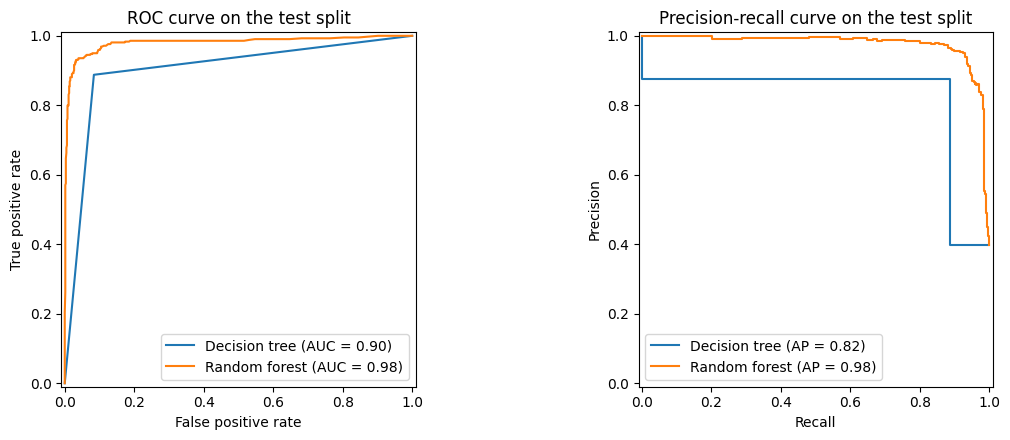

In [44]:
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

tree.fit(X_train, y_train)
tree_test_scores = tree.predict_proba(X_test)[:, 1]

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(12, 4.5))

for name, scores in [
    ("Decision tree", tree_test_scores),
    ("Random forest", rf_test_scores),
]:
    RocCurveDisplay.from_predictions(y_test, scores, name=name, ax=ax_roc)
    PrecisionRecallDisplay.from_predictions(y_test, scores, name=name, ax=ax_pr)

ax_roc.set(title="ROC curve on the test split", xlabel="False positive rate",
           ylabel="True positive rate")
ax_pr.set(title="Precision-recall curve on the test split", xlabel="Recall",
          ylabel="Precision")

fig.tight_layout()
plt.show()

In [45]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    rf, X_test, y_test, n_repeats=10, random_state=SEED, scoring="accuracy"
)

mdi = pd.Series(rf.feature_importances_, index=feature_names, name="MDI")
perm_accuracy = pd.Series(
    perm.importances_mean, index=feature_names, name="Mean accuracy drop"
)

print("Top 5 impurity importances")
print(mdi.nlargest(5).to_frame().to_string(float_format="{:.6f}".format))

print("\nTop 5 permutation importances")
print(perm_accuracy.nlargest(5).to_frame().to_string(float_format="{:.6f}".format))

feature = "capital_run_length_average"
related_features = ["capital_run_length_longest", "capital_run_length_total"]

print(f"\nMDI rank: {mdi.rank(ascending=False).loc[feature]:g}")
print(f"Permutation rank: {perm_accuracy.rank(ascending=False).loc[feature]:g}")
print(f"Mean test accuracy drop: {perm_accuracy.loc[feature]:.6f}")

train_features = pd.DataFrame(X_train, columns=feature_names)
correlations = train_features[related_features].corrwith(train_features[feature])
print("\nTraining correlations with capital_run_length_average")
print(correlations.round(3).to_string())

Top 5 impurity importances
                                MDI
char_freq_exclam           0.113624
char_freq_dollar           0.089327
word_freq_remove           0.083094
capital_run_length_average 0.066300
word_freq_free             0.065143

Top 5 permutation importances
                  Mean accuracy drop
word_freq_remove            0.030447
char_freq_exclam            0.015128
word_freq_hp                0.014462
char_freq_dollar            0.009039
word_freq_george            0.006089

MDI rank: 4
Permutation rank: 9.5
Mean test accuracy drop: 0.003235

Training correlations with capital_run_length_average
capital_run_length_longest    0.470
capital_run_length_total      0.165


### Results and interpretation

**Threshold.** The selected threshold was approximately 0.736667. On the training folds, it gave an out-of-fold false positive rate of 0.9494% and a recall of 82.18%. On the test split, precision was 97.77% and recall was 83.77%. The filter flagged 8 of 632 legitimate emails, giving a false positive rate of 1.27%. The 1% target was exceeded on the test split.

**Feature importance.** `capital_run_length_average` ranked fourth by impurity importance and tied for ninth by permutation importance. The feature contributed to impurity reduction in training splits, but shuffling it reduced test accuracy by only 0.32 percentage points on average. Its training correlation with `capital_run_length_longest` was 0.470. Because the longest run stays unchanged when the average is shuffled, it may preserve some of the same information in trees that use it. This could help explain why the average ranks higher by impurity reduction than by its effect on test accuracy.

## Part 3 - Voting

In [46]:
def hard_vote(predictions, weights=None):
    """Return the weighted majority label for each sample."""
    labels = np.asarray(predictions)
    n_models, n_samples = labels.shape
    model_weights = (
        [1] * n_models
        if weights is None
        else np.asarray(weights, dtype=object).tolist()
    )
    result = np.zeros(n_samples, dtype=int)

    for sample_index, sample_labels in enumerate(labels.T):
        counts = {0: 0}
        for label, weight in zip(sample_labels, model_weights):
            label = int(label)
            counts[label] = counts.get(label, 0) + weight
        result[sample_index] = max(counts, key=lambda label: (counts[label], -label))

    return result

In [47]:
from itertools import combinations

from sklearn.base import clone
from sklearn.ensemble import VotingClassifier

np.testing.assert_array_equal(hard_vote([[0, 1, 1], [0, 1, 0], [1, 1, 0]]), [0, 1, 0])
np.testing.assert_array_equal(hard_vote([[0, 1], [1, 0]]), [0, 0])
np.testing.assert_array_equal(hard_vote([[0, 1], [1, 0]], weights=[1, 2]), [1, 0])
np.testing.assert_array_equal(hard_vote([[2, 0], [2, 1], [0, 1]]), [2, 1])
np.testing.assert_array_equal(hard_vote([[2], [3]], weights=[0, 0]), [0])

fitted_members = {
    name: clone(model).fit(X_train, y_train)
    for name, model in members
}
member_test_predictions = {
    name: model.predict(X_test)
    for name, model in fitted_members.items()
}

hard = VotingClassifier(members, voting="hard")
soft = VotingClassifier(members, voting="soft")

manual_predictions = hard_vote(np.vstack(list(member_test_predictions.values())))
sklearn_predictions = hard.fit(X_train, y_train).predict(X_test)

agreement = np.mean(manual_predictions == sklearn_predictions)
print(f"Hard vote agreement with sklearn: {agreement:.6f}")

disagreement = {}
for left, right in combinations(member_test_predictions, 2):
    disagreement[f"{left} vs {right}"] = np.mean(
        member_test_predictions[left] != member_test_predictions[right]
    )

print("\nPairwise disagreement on the test split")
print(pd.Series(disagreement, name="Disagreement").to_string(float_format="{:.2%}".format))

Hard vote agreement with sklearn: 1.000000

Pairwise disagreement on the test split
lr vs knn      5.33%
lr vs tree     8.66%
knn vs tree   10.37%


In [48]:
voting_scores = {
    "lr": cv_scores["lr"],
    "knn": cv_accuracy(knn),
    "tree": cv_scores["tree"],
    "hard": cv_accuracy(hard),
    "soft": cv_accuracy(soft),
}

best_member = max(
    (name for name, _ in members),
    key=lambda name: voting_scores[name].mean(),
)

part3_scores = {
    **voting_scores,
    f"hard - {best_member}": voting_scores["hard"] - voting_scores[best_member],
    f"soft - {best_member}": voting_scores["soft"] - voting_scores[best_member],
}

print(f"Best individual member by mean CV accuracy: {best_member}")
print(fold_table(part3_scores).to_string(float_format="{:.6f}".format))

Best individual member by mean CV accuracy: lr
            Fold 1   Fold 2    Fold 3    Fold 4   Fold 5     Mean      Std
lr        0.930269 0.936609  0.947702  0.936508 0.947619 0.939741 0.006862
knn       0.914422 0.922345  0.938193  0.915873 0.933333 0.924833 0.009441
tree      0.912837 0.903328  0.890650  0.884127 0.914286 0.901045 0.011949
hard      0.933439 0.942948  0.946117  0.933333 0.950794 0.941326 0.006947
soft      0.938193 0.939778  0.941363  0.938095 0.950794 0.941645 0.004728
hard - lr 0.003170 0.006339 -0.001585 -0.003175 0.003175 0.001585 0.003474
soft - lr 0.007924 0.003170 -0.006339  0.001587 0.003175 0.001903 0.004637


### Results and interpretation

**Voting agreement.** The manual hard vote matched scikit-learn on all 1051 test emails. Logistic regression and k-nearest neighbors disagreed on 5.33% of emails. The decision tree disagreed with logistic regression on 8.66% and with k-nearest neighbors on 10.37%.

**Hard voting.** Logistic regression was the best individual member by mean CV accuracy at 0.939741. Hard voting reached 0.941326. Its mean paired gain of 0.001585 was within the paired standard deviation of 0.003474, so the folds do not show a clear improvement over logistic regression.

**Soft voting.** Soft voting reached a mean CV accuracy of 0.941645. Its mean paired gain over logistic regression was 0.001903, within the paired standard deviation of 0.004637. The folds do not show a clear improvement for soft voting either.

## Part 4 - Stacking

In [49]:
from sklearn.ensemble import StackingClassifier

stack_oof = np.column_stack([
    cross_val_predict(
        model, X_train, y_train, cv=cv, method="predict_proba"
    )[:, 1]
    for _, model in members
])

stack_test = np.column_stack([
    fitted_members[name].predict_proba(X_test)[:, 1]
    for name, _ in members
])

meta_oof = LogisticRegression().fit(stack_oof, y_train)
stack = StackingClassifier(
    members, LogisticRegression(), cv=cv
).fit(X_train, y_train)

max_coef_diff = np.max(np.abs(meta_oof.coef_ - stack.final_estimator_.coef_))
same_predictions = np.array_equal(
    meta_oof.predict(stack_test), stack.predict(X_test)
)

print(f"OOF matrix shape: {stack_oof.shape}")
print(f"Largest absolute coefficient difference: {max_coef_diff:.12g}")
print(f"Identical test predictions: {same_predictions}")
print(f"Manual stacking test accuracy: {meta_oof.score(stack_test, y_test):.6f}")
print(f"Scikit-learn stacking test accuracy: {stack.score(X_test, y_test):.6f}")

OOF matrix shape: (3153, 3)
Largest absolute coefficient difference: 0
Identical test predictions: True
Manual stacking test accuracy: 0.934348
Scikit-learn stacking test accuracy: 0.934348


In [50]:
stack_in_sample = np.column_stack([
    fitted_members[name].predict_proba(X_train)[:, 1]
    for name, _ in members
])

meta_naive = LogisticRegression().fit(stack_in_sample, y_train)

coef_table = pd.DataFrame(
    {"Naive": meta_naive.coef_[0], "OOF": meta_oof.coef_[0]},
    index=[name for name, _ in members],
)
print("Meta-model coefficients")
print(coef_table.to_string(float_format="{:.6f}".format))

tree_col = coef_table.index.get_loc("tree")
tree_in_sample_accuracy = fitted_members["tree"].score(X_train, y_train)
tree_oof_accuracy = np.mean((stack_oof[:, tree_col] > 0.5) == y_train)

print(f"\nTree in-sample accuracy: {tree_in_sample_accuracy:.6f}")
print(f"Tree out-of-fold accuracy: {tree_oof_accuracy:.6f}")

Meta-model coefficients
        Naive      OOF
lr   1.992193 3.821031
knn  1.843190 2.970286
tree 8.269628 1.366585

Tree in-sample accuracy: 1.000000
Tree out-of-fold accuracy: 0.901047


In [51]:
stack_cv = cv_accuracy(stack)
soft_cv = voting_scores["soft"]
best_member_cv = voting_scores[best_member]

part4_scores = {
    "stack": stack_cv,
    "soft": soft_cv,
    best_member: best_member_cv,
    f"stack - {best_member}": stack_cv - best_member_cv,
    "stack - soft": stack_cv - soft_cv,
}

print(fold_table(part4_scores).to_string(float_format="{:.6f}".format))

                Fold 1   Fold 2    Fold 3   Fold 4   Fold 5      Mean      Std
stack         0.930269 0.942948  0.942948 0.939683 0.950794  0.941328 0.006631
soft          0.938193 0.939778  0.941363 0.938095 0.950794  0.941645 0.004728
lr            0.930269 0.936609  0.947702 0.936508 0.947619  0.939741 0.006862
stack - lr    0.000000 0.006339 -0.004754 0.003175 0.003175  0.001587 0.003751
stack - soft -0.007924 0.003170  0.001585 0.001587 0.000000 -0.000316 0.003934


### Results and interpretation

**Manual stacking.** The manual stack and scikit-learn had identical meta-model coefficients and predicted the same label for every test email. Both achieved a test accuracy of 0.934348.

**Naive and out-of-fold stacking.** The tree coefficient fell from 8.269628 in the naive stack to 1.366585 in the out-of-fold stack. The tree classified every row it trained on correctly, while its out-of-fold accuracy was 90.10%. The naive meta-model sees the tree reproduce labels it already learned, so it gives the tree more weight than the meta-model trained on predictions for held-out rows.

**Cross-validation.** Stacking had a mean CV accuracy of 0.941328. Its mean paired gain over logistic regression was 0.001587, within the paired standard deviation of 0.003751. Its mean paired difference against soft voting was -0.000316, also within the paired standard deviation of 0.003934. The fold results do not distinguish stacking from either model.

## Part 5 - AdaBoost and label noise

In [52]:
import math


def adaboost_step(y_true, y_pred, weights):
    """Return the learner weight and the normalized row weights."""
    wrong = np.asarray(y_true) != np.asarray(y_pred)
    new_weights = np.array(weights, dtype=float, copy=True)
    error = new_weights[wrong].sum() / new_weights.sum()

    if error == 0:
        return math.inf, new_weights / new_weights.sum()

    alpha = math.log((1 - error) / error)
    new_weights[wrong] *= math.exp(alpha)
    return alpha, new_weights / new_weights.sum()

In [53]:
x = np.arange(1, 11)
y_toy = np.array([1, 1, 1, 0, 0, 0, 1, 1, 1, 0])
toy_stumps = [
    np.where(x <= 3.5, 1, 0),
    np.where(x <= 9.5, 1, 0),
    np.where(x <= 6.5, 0, 1),
]

weights = np.full(len(y_toy), 0.1)

for round_number, predictions in enumerate(toy_stumps, start=1):
    error = weights[predictions != y_toy].sum() / weights.sum()
    alpha, weights = adaboost_step(y_toy, predictions, weights)
    print(f"Toy round {round_number}: error = {error:.3f}, alpha = {alpha:.3f}")
    print("New weights:", weights.round(3))

ada.fit(X_train, y_train)
weights = np.full(len(y_train), 1 / len(y_train))
manual_errors = []
manual_alphas = []

for stump in ada.estimators_[:5]:
    predictions = stump.predict(X_train)
    error = weights[predictions != y_train].sum() / weights.sum()
    alpha, weights = adaboost_step(y_train, predictions, weights)
    manual_errors.append(error)
    manual_alphas.append(alpha)

max_error_diff = np.max(np.abs(np.array(manual_errors) - ada.estimator_errors_[:5]))
max_alpha_diff = np.max(np.abs(np.array(manual_alphas) - ada.estimator_weights_[:5]))

print(f"\nLargest error difference over first five rounds: {max_error_diff:.3e}")
print(f"Largest alpha difference over first five rounds: {max_alpha_diff:.3e}")

Toy round 1: error = 0.300, alpha = 0.847
New weights: [0.071 0.071 0.071 0.071 0.071 0.071 0.167 0.167 0.167 0.071]
Toy round 2: error = 0.214, alpha = 1.299
New weights: [0.045 0.045 0.045 0.167 0.167 0.167 0.106 0.106 0.106 0.045]
Toy round 3: error = 0.182, alpha = 1.504
New weights: [0.125 0.125 0.125 0.102 0.102 0.102 0.065 0.065 0.065 0.125]

Largest error difference over first five rounds: 1.110e-16
Largest alpha difference over first five rounds: 8.882e-16


CV-selected round: 386
Mean validation accuracy at selected round: 0.943548
Test error at selected round: 0.060894
First round with minimum test error: 372
Minimum test error: 0.060894
Test error gap: 0.000000
Test standard error at selected round: 0.007376
Gap exceeds one standard error: False


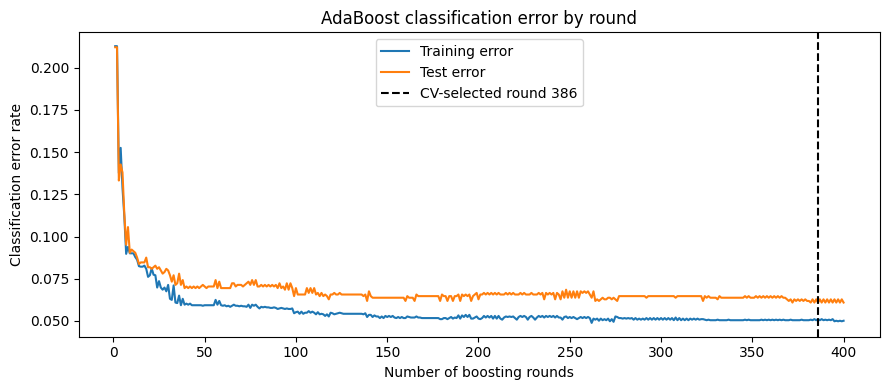

In [54]:
validation_curves = []

for train_index, validation_index in cv.split(X_train, y_train):
    fold_ada = clone(ada).fit(X_train[train_index], y_train[train_index])
    fold_accuracy = list(fold_ada.staged_score(
        X_train[validation_index], y_train[validation_index]
    ))
    validation_curves.append(fold_accuracy)

mean_validation_accuracy = np.mean(validation_curves, axis=0)
chosen_index = np.argmax(mean_validation_accuracy)
chosen_round = chosen_index + 1

train_error_by_round = 1 - np.array(list(ada.staged_score(X_train, y_train)))
test_accuracy_by_round = np.array(list(ada.staged_score(X_test, y_test)))
test_error_by_round = 1 - test_accuracy_by_round
best_test_index = np.argmin(test_error_by_round)

chosen_test_accuracy = test_accuracy_by_round[chosen_index]
chosen_test_se = np.sqrt(
    chosen_test_accuracy * (1 - chosen_test_accuracy) / len(y_test)
)
test_error_gap = test_error_by_round[chosen_index] - test_error_by_round[best_test_index]

print(f"CV-selected round: {chosen_round}")
print(f"Mean validation accuracy at selected round: {mean_validation_accuracy[chosen_index]:.6f}")
print(f"Test error at selected round: {test_error_by_round[chosen_index]:.6f}")
print(f"First round with minimum test error: {best_test_index + 1}")
print(f"Minimum test error: {test_error_by_round[best_test_index]:.6f}")
print(f"Test error gap: {test_error_gap:.6f}")
print(f"Test standard error at selected round: {chosen_test_se:.6f}")
print(f"Gap exceeds one standard error: {test_error_gap > chosen_test_se}")

rounds = np.arange(1, len(test_error_by_round) + 1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(rounds, train_error_by_round, label="Training error")
ax.plot(rounds, test_error_by_round, label="Test error")
ax.axvline(chosen_round, color="black", linestyle="--",
           label=f"CV-selected round {chosen_round}")
ax.set(
    title="AdaBoost classification error by round",
    xlabel="Number of boosting rounds",
    ylabel="Classification error rate",
)
ax.legend()
fig.tight_layout()
plt.show()

In [55]:
def flip_labels(y, rate, seed):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(y), size=round(rate * len(y)), replace=False)
    y_noisy = y.copy()
    y_noisy[idx] = 1 - y_noisy[idx]
    return y_noisy, idx


ada200 = AdaBoostClassifier(n_estimators=200, random_state=SEED)
noise_models = {"tree": tree, "rf": rf, "ada200": ada200}

clean_accuracy = {
    name: clone(model).fit(X_train, y_train).score(X_test, y_test)
    for name, model in noise_models.items()
}
noisy_accuracy = {name: [] for name in noise_models}
weight_shares = []

for draw in range(5):
    y_noisy, flipped = flip_labels(y_train, 0.20, SEED + draw)

    for name, model in noise_models.items():
        noisy_model = clone(model).fit(X_train, y_noisy)
        noisy_accuracy[name].append(noisy_model.score(X_test, y_test))

        if name == "ada200":
            weights = np.full(len(y_train), 1 / len(y_train))
            for stump in noisy_model.estimators_:
                _, weights = adaboost_step(
                    y_noisy, stump.predict(X_train), weights
                )
            weight_shares.append([len(flipped) / len(y_train), weights[flipped].sum()])

losses = {
    name: clean_accuracy[name] - np.asarray(noisy_accuracy[name])
    for name in noise_models
}

noise_summary = pd.DataFrame({
    "Clean accuracy": pd.Series(clean_accuracy),
    "Noisy mean": {name: np.mean(scores) for name, scores in noisy_accuracy.items()},
    "Noisy std": {name: np.std(scores) for name, scores in noisy_accuracy.items()},
    "Loss mean": {name: loss.mean() for name, loss in losses.items()},
    "Loss std": {name: loss.std() for name, loss in losses.items()},
})

draw_labels = [f"Draw {i}" for i in range(1, 6)]
loss_table = pd.DataFrame(losses, index=draw_labels).T

paired_loss_diffs = {
    f"{left} - {right}": losses[left] - losses[right]
    for left, right in combinations(losses, 2)
}

share_table = pd.DataFrame(
    weight_shares, index=draw_labels, columns=["Initial share", "Final share"]
)
share_table.loc["Mean"] = share_table.mean()
share_table.loc["Std"] = share_table.loc[draw_labels].std(ddof=0)

print("Test accuracy and loss under label noise")
print(noise_summary.to_string(float_format="{:.6f}".format))

print("\nAccuracy losses by draw")
print(loss_table.to_string(float_format="{:.6f}".format))

print("\nPaired differences in accuracy loss")
print(fold_table(paired_loss_diffs).rename(
    columns={f"Fold {i}": f"Draw {i}" for i in range(1, 6)}
).to_string(float_format="{:.6f}".format))

print("\nAdaBoost weight share on flipped rows")
print(share_table.to_string(float_format="{:.6f}".format))

Test accuracy and loss under label noise
        Clean accuracy  Noisy mean  Noisy std  Loss mean  Loss std
tree          0.904853    0.735109   0.017280   0.169743  0.017280
rf            0.949572    0.902759   0.003729   0.046813  0.003729
ada200        0.937203    0.912274   0.005939   0.024929  0.005939

Accuracy losses by draw
         Draw 1   Draw 2   Draw 3   Draw 4   Draw 5
tree   0.180780 0.162702 0.185538 0.138915 0.180780
rf     0.045671 0.040913 0.048525 0.046622 0.052331
ada200 0.024738 0.016175 0.020932 0.031399 0.031399

Paired differences in accuracy loss
                Draw 1   Draw 2   Draw 3   Draw 4   Draw 5     Mean      Std
tree - rf     0.135109 0.121789 0.137012 0.092293 0.128449 0.122931 0.016230
tree - ada200 0.156042 0.146527 0.164605 0.107517 0.149382 0.144814 0.019660
rf - ada200   0.020932 0.024738 0.027593 0.015224 0.020932 0.021884 0.004169

AdaBoost weight share on flipped rows
        Initial share  Final share
Draw 1       0.200127     0.395567
Draw

### Results and interpretation

**AdaBoost update.** The three toy rounds reproduced the lecture's weighted errors of 0.300, 0.214 and 0.182 and learner weights of 0.847, 1.299 and 1.504. After each update, the rows misclassified by that stump carried half of the total weight. The errors and learner weights for the first five scikit-learn stumps agreed with the manual calculation to floating-point precision.

**Number of rounds.** Cross-validation selected 386 rounds. The minimum test error first occurred at round 372. The test error at both rounds was 0.060894, so the gap of zero was smaller than the test standard error of 0.007376 at the selected round.

**Label noise.** The decision tree lost the most accuracy. Its mean loss was 0.169743, compared with 0.046813 for the random forest and 0.024929 for AdaBoost. The paired mean loss differences were 0.122931 for tree versus forest, 0.144814 for tree versus AdaBoost and 0.021884 for forest versus AdaBoost. Each exceeded its paired standard deviation of 0.016230, 0.019660 and 0.004169, respectively.

**Why the models responded differently.** A depth-one stump has limited capacity to fit scattered flipped labels, while a fully grown tree can create more specific splits that fit noisy training labels.Averaging many such trees in the forest reduces the effect of individual noisy splits, so the forest lost far less than the single tree (0.0468 versus 0.1697). The flipped rows started with 20.01% of the total weight and ended with 39.60% on average. Despite this increase, AdaBoost lost less test accuracy than the other two models. The limited capacity of each stump is one plausible explanation for the observed ranking on this split and across these five draws.